# 실험 008 — MobileNetV3 Large + EfficientNet-B0 이종 앙상블

시작 분할 seed는 42입니다. SEED를 1로 바꾸면 같은 구성으로 다시 검증합니다.
첫 strong 자리를 MobileNetV3 Large로 교체하고, 나머지 B0 세 개는 같은 분할 seed의 실험 007에서 재사용합니다.
최종 제출 CSV는 조건부 T0.3과 조건부 T0.3 TTA 두 개입니다.
실제 실행 위치는 프로젝트 루트이며 별도 커널에서 실행합니다.


## 실행 전 사전 준비

### 모듈
Colab은 필요한 모듈이 모두 설치되어 있습니다. 로컬이라면:
```shell
# 본인 환경(CPU/CUDA)에 맞는 PyTorch 설치: https://pytorch.org/get-started/locally/
pip3 install torch torchvision
pip3 install -U scikit-learn matplotlib
```

### 데이터 파일
운영진이 배포한 데이터를 노트북과 같은 폴더에 압축해제해 주세요 (Colab 은 `/content`).
```
📁root
 ├─📁train
 │  ├─📁6e      ← 6공학관 (label 0)
 │  └─📁it      ← IT관   (label 1)
 ├─📁test       ← 테스트 500장 (Public 250 + Private 250)
 └─📜baseline.ipynb
```


## 모듈 불러오기 & 시드 고정

재현성을 위해 모든 난수 시드를 고정합니다. 시드가 고정되어 있어야 "내가 바꾼 것 때문에 점수가 오른 것인지, 운이 좋았던 것인지"를 구분할 수 있습니다.

In [ ]:
import csv
import os
import random
import shutil
import subprocess
import time

import numpy as np
import torch
import torch.nn as nn
import torchvision
from torchvision import transforms, datasets
from torch.utils.data import DataLoader, Dataset, Subset
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
from PIL import Image


def seed_everything(seed: int):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    os.environ['PYTHONHASHSEED'] = str(seed)


SEED = 1
seed_everything(SEED)

In [2]:
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
print('사용 장치:', device)
if torch.cuda.is_available():
    print(torch.cuda.get_device_name())

사용 장치: cuda:0
NVIDIA GeForce RTX 3080


## 하이퍼 파라미터

In [3]:
params = {
    'epoch': 50,
    'early_stopping': True,
    'min_epochs': 5,       # 각 학습률의 최소 학습 epoch, 이후부터 미개선 횟수 집계
    'patience': 5,
    'batch_size': 32,
    'learning_rates': (1e-3, 3e-4, 1e-4),
    'valid_ratio': 0.15,   # 학습 2,906장 중 검증으로 떼어둘 비율
    'workers': 0,          # Windows 노트북의 워커 프로세스 멈춤 방지; 모든 실험에 공통 적용
    'num_show_img': 5,     # 데이터 확인용 표시 개수 (학습과 무관)
}

In [4]:
# label 0 = 6공학관(6e), label 1 = IT관(it)
class_names = {0: '6e', 1: 'it'}

RUN_SEEDS = tuple(range(SEED, SEED + 4))
AUGMENTATION_BY_SEED = dict(zip(RUN_SEEDS, ("strong", "strong", "erasing", "perspective")))
print("분할 시드:", SEED, "/ 모델 시드:", RUN_SEEDS)

MODEL_NAMES = ("mobilenet_v3_large", "efficientnet_b0", "efficientnet_b0", "efficientnet_b0")
print("모델 구성:", MODEL_NAMES)


분할 시드: 42 / 모델 시드: (42, 43, 44, 45)
모델 구성: ('mobilenet_v3_large', 'efficientnet_b0', 'efficientnet_b0', 'efficientnet_b0')


## 결과 폴더와 제출 이름

실행 노트북은 baseline_test2.ipynb입니다. SEED를 바꾸면 분할·모델 seed·결과 폴더가 함께 바뀝니다.
결과는 실험결과/008_이종모델앙상블/seed_{SEED}/에 저장합니다.
최종 제출 CSV는 submission_{SEED}_T0.3.csv와 submission_{SEED}_T0.3_TTA.csv입니다.
학습 시작 전에 노트북을 저장합니다. 같은 seed로 재실행하면 008의 해당 결과를 덮어씁니다.


In [5]:
from pathlib import Path

BASE_DIR = Path.cwd().resolve()
assert (BASE_DIR / "train").is_dir(), f"작업 폴더에 train이 없습니다: {BASE_DIR}"

RESULT_DIR = BASE_DIR / "실험결과" / "008_이종모델앙상블" / f"seed_{SEED}"
GRAPH_DIR = RESULT_DIR / "graphs"
CHECKPOINT_DIR = RESULT_DIR / "checkpoints"
EPOCH_DIR = RESULT_DIR / "epochs"
CODE_DIR = RESULT_DIR / "코드"

GRAPH_DIR.mkdir(parents=True, exist_ok=True)
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
EPOCH_DIR.mkdir(parents=True, exist_ok=True)
CODE_DIR.mkdir(parents=True, exist_ok=True)

print("그래프 저장 폴더:", GRAPH_DIR)
print("학습 가중치 저장 폴더:", CHECKPOINT_DIR)

print("epoch CSV 저장 폴더:", EPOCH_DIR)

SOURCE_DIR = BASE_DIR / "실험결과" / "007_Strong기반앙상블" / f"seed_{SEED}"
print("재사용할 007 결과:", SOURCE_DIR)


그래프 저장 폴더: C:\Users\행조\OneDrive\문서\ChatGPT\aid mini 대회\실험결과\008_이종모델앙상블\seed_42\graphs
학습 가중치 저장 폴더: C:\Users\행조\OneDrive\문서\ChatGPT\aid mini 대회\실험결과\008_이종모델앙상블\seed_42\checkpoints
epoch CSV 저장 폴더: C:\Users\행조\OneDrive\문서\ChatGPT\aid mini 대회\실험결과\008_이종모델앙상블\seed_42\epochs
재사용할 007 결과: C:\Users\행조\OneDrive\문서\ChatGPT\aid mini 대회\실험결과\007_Strong기반앙상블\seed_42


## 모델 정의 — model_test2.py 생성

첫 모델은 ImageNet 사전학습 MobileNetV3 Large입니다. 나머지는 007의 EfficientNet-B0 가중치를 사용합니다.
최종 ZIP에는 두 구조의 학습된 전체 가중치를 담아 추론 중 다운로드 없이 복원합니다.


In [6]:
%%writefile model_test2.py
import torch
import torch.nn as nn
from torchvision import models
from torchvision import transforms
from torchvision.transforms import functional as F

IMG_SIZE = 256
NORM_MEAN = (0.485, 0.456, 0.406)
NORM_STD = (0.229, 0.224, 0.225)
PAD_FILL = tuple(round(value * 255) for value in NORM_MEAN)
CONSENSUS_TEMPERATURE = 0.3
DISAGREEMENT_TEMPERATURE = 0.7


def resize_pad(image):
	width, height = image.size
	scale = IMG_SIZE / max(width, height)
	new_width = max(1, round(width * scale))
	new_height = max(1, round(height * scale))
	image = F.resize(image, [new_height, new_width], antialias=True)
	left = (IMG_SIZE - new_width) // 2
	top = (IMG_SIZE - new_height) // 2
	return F.pad(image, [left, top, IMG_SIZE - new_width - left, IMG_SIZE - new_height - top], fill=PAD_FILL)


class RandomAreaCrop:
	def __init__(self, scale):
		self.scale = scale

	def __call__(self, image):
		top, left, height, width = transforms.RandomResizedCrop.get_params(image, scale=self.scale, ratio=(0.75, 4 / 3))
		return F.crop(image, top, left, height, width)


def build_valid_transform():
	return transforms.Compose([
		transforms.Lambda(resize_pad),
		transforms.ToTensor(),
		transforms.Normalize(NORM_MEAN, NORM_STD),
	])


def combine_probabilities(member_probs):
	assert (member_probs.ndim == 2) and (member_probs.shape[1] == 4)
	votes = member_probs >= 0.5
	unanimous = (votes == votes[:, :1]).all(dim=1, keepdim=True)
	middle_mean = member_probs.sort(dim=1).values[:, 1:3].mean(dim=1, keepdim=True)
	probs = torch.where(unanimous, member_probs.mean(dim=1, keepdim=True), middle_mean)
	temperatures = torch.where(unanimous, CONSENSUS_TEMPERATURE, DISAGREEMENT_TEMPERATURE)
	return torch.sigmoid(torch.logit(probs) / temperatures)


def build_model(model_name, pretrained=False):
	if model_name == "efficientnet_b0":
		weights = models.EfficientNet_B0_Weights.IMAGENET1K_V1 if pretrained else None
		net = models.efficientnet_b0(weights=weights)
	elif model_name == "mobilenet_v3_large":
		weights = models.MobileNet_V3_Large_Weights.IMAGENET1K_V1 if pretrained else None
		net = models.mobilenet_v3_large(weights=weights)
	else:
		raise ValueError(f"알 수 없는 모델: {model_name}")
	net.classifier[-1] = nn.Linear(net.classifier[-1].in_features, 1)
	return net


class MixedEnsemble(nn.Module):
	def __init__(self, model_names, state_dicts):
		super().__init__()
		assert len(model_names) == len(state_dicts) == 4, "모델 이름과 가중치가 각각 4개 필요합니다."
		self.models = nn.ModuleList()
		for model_name, state_dict in zip(model_names, state_dicts):
			model = build_model(model_name)
			model.load_state_dict(state_dict)
			self.models.append(model)

	def member_probabilities(self, inputs, tta=False):
		# CPU 제출 재현과의 수치 차이를 줄이기 위해 추론에서는 TF32를 끕니다.
		with torch.backends.cudnn.flags(enabled=torch.backends.cudnn.enabled, benchmark=torch.backends.cudnn.benchmark, deterministic=torch.backends.cudnn.deterministic, allow_tf32=False):
			probs = torch.cat([torch.sigmoid(model(inputs)) for model in self.models], dim=1)
			if tta:
				flipped = inputs.flip(dims=[3])
				flipped_probs = torch.cat([torch.sigmoid(model(flipped)) for model in self.models], dim=1)
				probs = (probs + flipped_probs) / 2
		return probs

	def forward(self, inputs, tta=False):
		return combine_probabilities(self.member_probabilities(inputs, tta=tta))


Overwriting model_test2.py


In [7]:
import importlib
import model_test2 as model_module

importlib.reload(model_module)


<module 'model_test2' from 'c:\\Users\\행조\\OneDrive\\문서\\ChatGPT\\aid mini 대회\\model_test2.py'>

### 파라미터 제한

각 실행에서 모델을 새로 만들고 총 파라미터 수가 20,000,000 이하인지 확인합니다.


In [8]:
PARAM_LIMIT = 20_000_000
print("MobileNetV3 Large 1개 + EfficientNet-B0 3개 / 예상 파라미터 16,229,800")


MobileNetV3 Large 1개 + EfficientNet-B0 3개 / 예상 파라미터 16,229,800


## Strong 기반 증강

네 모델 모두 크롭 면적 50–100%, 밝기·대비 ±40%, 채도 ±30%, 좌우 반전 확률 0.5를 사용합니다.
SEED·SEED+1은 strong, SEED+2는 strong+가림, SEED+3은 strong+원근 변형입니다.
가림은 확률 10%, 면적 2–10%이며, 원근 변형은 확률 30%, distortion_scale=0.15입니다.
검증·추론은 원본 비율을 유지해 긴 변을 256으로 맞춘 뒤 중앙 패딩합니다.
학습도 영역을 자른 뒤 같은 비율 보존·패딩 과정을 거칩니다.


In [9]:
data_path = BASE_DIR / "train"
IMG_SIZE = model_module.IMG_SIZE
NORM_MEAN = model_module.NORM_MEAN
NORM_STD = model_module.NORM_STD

AUGMENTATION_SETTINGS = {
	"strong": {"scale_min": 0.5, "brightness": 0.4, "contrast": 0.4, "saturation": 0.3, "erase_p": 0.0, "perspective_p": 0.0, "distortion_scale": 0.0},
	"erasing": {"scale_min": 0.5, "brightness": 0.4, "contrast": 0.4, "saturation": 0.3, "erase_p": 0.1, "perspective_p": 0.0, "distortion_scale": 0.0},
	"perspective": {"scale_min": 0.5, "brightness": 0.4, "contrast": 0.4, "saturation": 0.3, "erase_p": 0.0, "perspective_p": 0.3, "distortion_scale": 0.15},
}
train_transforms = {}
for name, settings in AUGMENTATION_SETTINGS.items():
	operations = [
		model_module.RandomAreaCrop(scale=(settings["scale_min"], 1.0)),
		transforms.RandomHorizontalFlip(p=0.5),
		transforms.ColorJitter(brightness=settings["brightness"], contrast=settings["contrast"], saturation=settings["saturation"]),
	]
	if settings["perspective_p"] > 0:
		operations.append(transforms.RandomPerspective(distortion_scale=settings["distortion_scale"], p=settings["perspective_p"], fill=model_module.PAD_FILL))
	operations.extend([
		transforms.Lambda(model_module.resize_pad),
		transforms.ToTensor(),
		transforms.Normalize(NORM_MEAN, NORM_STD),
	])
	if settings["erase_p"] > 0:
		operations.append(transforms.RandomErasing(p=settings["erase_p"], scale=(0.02, 0.1), value=0))
	train_transforms[name] = transforms.Compose(operations)

train_transform = train_transforms["strong"]
valid_transform = model_module.build_valid_transform()
full_train = datasets.ImageFolder(data_path, train_transform)
full_valid = datasets.ImageFolder(data_path, valid_transform)
print("클래스 → 라벨 매핑:", full_train.class_to_idx)
print("전체 이미지 수:", len(full_train))
print("입력 크기:", IMG_SIZE, "비율 보존 및 중앙 패딩")


클래스 → 라벨 매핑: {'6e': 0, 'it': 1}
전체 이미지 수: 2906
입력 크기: 256 비율 보존 및 중앙 패딩


### 학습·검증 분할

분할 seed와 검증 비율은 007과 같습니다. MobileNet은 같은 학습 사진으로 새로 학습하고,
세 B0는 해당 분할의 007 체크포인트를 재사용합니다.


In [10]:
labels = [y for _, y in full_train.samples]
train_idx, valid_idx = train_test_split(
    list(range(len(full_train))),
    test_size=params['valid_ratio'],
    stratify=labels,
    random_state=SEED,
)

data_sets = {
    'train': Subset(full_train, train_idx),
    'valid': Subset(full_valid, valid_idx),
}
print(f"train: {len(data_sets['train'])}장 / valid: {len(data_sets['valid'])}장")

train: 2470장 / valid: 436장


In [11]:
g = torch.Generator()
g.manual_seed(SEED)

dataloaders = {
    'train': DataLoader(data_sets['train'], batch_size=params['batch_size'],
                        shuffle=True, num_workers=params['workers'], generator=g),
    'valid': DataLoader(data_sets['valid'], batch_size=params['batch_size'],
                        shuffle=False, num_workers=params['workers']),
}
print('배치 수 — train: %d / valid: %d' % (len(dataloaders['train']), len(dataloaders['valid'])))

배치 수 — train: 78 / valid: 14


### 데이터 확인

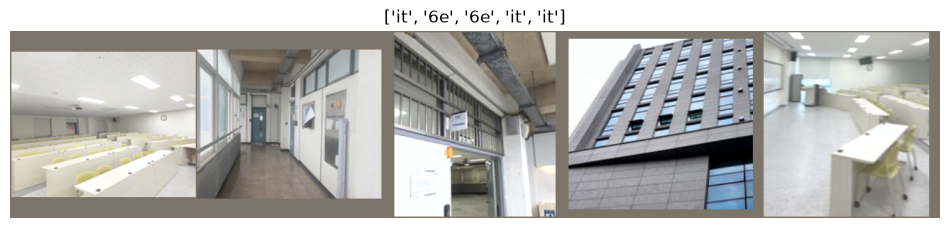

In [12]:
def img_show(tensor, title=None):
    arr = tensor.numpy().transpose((1, 2, 0))
    arr = arr * np.array(NORM_STD) + np.array(NORM_MEAN)  # 정규화 되돌리기 (표시용)
    arr = np.clip(arr, 0, 1)
    plt.figure(figsize=(12, 4))
    plt.imshow(arr)
    plt.axis('off')
    if title is not None:
        plt.title(title)
    plt.show()


inputs, classes = next(iter(dataloaders['train']))
out = torchvision.utils.make_grid(inputs[:params['num_show_img']])
img_show(out, title=[class_names[int(c)] for c in classes[:params['num_show_img']]])

## MobileNet 학습

MobileNet 한 개를 strong 증강으로 새로 학습합니다.
학습률은 0.001 → 0.0003 → 0.0001, 단계별 최소 5 epoch와 미개선 5회, 최대 50 epoch입니다.
전체 최저 검증 Log Loss 가중치를 선택합니다.
007은 별도 커널에서 실행하고, MobileNet 학습 뒤 B0 재사용 단계에서 완료 여부와 설정을 확인합니다.


In [13]:
def run_epoch(model, loader, criterion, optimizer=None):
    """optimizer가 주어지면 학습, 아니면 평가. (평균 loss, 정확도)를 반환."""
    training = optimizer is not None
    model.train() if training else model.eval()

    total_loss, total_correct, total_n = 0.0, 0, 0
    with torch.set_grad_enabled(training):
        for inputs, targets in loader:
            inputs = inputs.to(device)
            targets = targets.float().unsqueeze(1).to(device)  # (B,) -> (B,1)

            logits = model(inputs)
            loss = criterion(logits, targets)

            if training:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()

            probs = torch.sigmoid(logits)
            preds = (probs >= 0.5).float()
            total_loss += loss.item() * inputs.size(0)
            total_correct += (preds == targets).sum().item()
            total_n += inputs.size(0)

    return total_loss / total_n, total_correct / total_n


def train_model(model, dataloaders, criterion, optimizer, num_epochs, epoch_csv, early_stopping, min_epochs, patience, learning_rates):
	assert min_epochs > 0
	assert patience > 0
	assert len(learning_rates) > 0
	assert all(rate > 0 for rate in learning_rates)
	since = time.time()
	history = {'train_loss': [], 'train_acc': [], 'valid_loss': [], 'valid_acc': []}
	best_acc, best_loss, best_epoch = -float('inf'), float('inf'), -1
	stage_index, stage_epochs = 0, 0
	stage_best_loss = float('inf')
	epochs_without_improvement = 0
	epoch_writer = csv.writer(epoch_csv)
	epoch_writer.writerow(('epoch', 'learning_rate', 'lr_stage', 'stage_epoch', 'train_loss', 'train_acc', 'valid_loss', 'valid_acc'))

	for epoch in range(1, num_epochs + 1):
		learning_rate = learning_rates[stage_index]
		for group in optimizer.param_groups:
			group['lr'] = learning_rate
		stage_epochs += 1
		tr_loss, tr_acc = run_epoch(model, dataloaders['train'], criterion, optimizer)
		va_loss, va_acc = run_epoch(model, dataloaders['valid'], criterion)

		history['train_loss'].append(tr_loss)
		history['train_acc'].append(tr_acc)
		history['valid_loss'].append(va_loss)
		history['valid_acc'].append(va_acc)
		epoch_writer.writerow((epoch, learning_rate, stage_index + 1, stage_epochs, tr_loss, tr_acc, va_loss, va_acc))
		epoch_csv.flush()
		print(f'Epoch {epoch}/{num_epochs} | lr {learning_rate:g} | train loss {tr_loss:.4f}, acc {tr_acc:.3f} | valid loss {va_loss:.4f}, acc {va_acc:.3f}')

		if (va_loss < best_loss) or ((va_loss == best_loss) and (va_acc > best_acc)):
			best_acc, best_loss, best_epoch = va_acc, va_loss, epoch
			torch.save(model.state_dict(), pt_file_name)
			print(f'  ↳ best Log Loss 갱신! {pt_file_name} 저장')

		if va_loss < stage_best_loss:
			stage_best_loss = va_loss
			epochs_without_improvement = 0
		elif stage_epochs > min_epochs:
			epochs_without_improvement += 1

		if epochs_without_improvement >= patience:
			if stage_index + 1 < len(learning_rates):
				stage_index += 1
				stage_epochs = 0
				stage_best_loss = float('inf')
				epochs_without_improvement = 0
				print(f'다음 epoch부터 학습률 {learning_rates[stage_index]:g} 적용')
			elif early_stopping:
				print(f'조기 종료: epoch {epoch}, 마지막 학습률에서 Log Loss {patience}회 연속 미개선')
				break

	elapsed = time.time() - since
	print(f'\n학습 완료 ({elapsed // 60:.0f}분 {elapsed % 60:.0f}초)')
	print(f'best: epoch {best_epoch}, valid acc {best_acc:.4f}, log loss {best_loss:.4f}')
	return history, best_epoch, best_loss


In [14]:
results = []



모델: mobilenet_v3_large / seed: 42 / 증강: strong
Downloading: "https://download.pytorch.org/models/mobilenet_v3_large-8738ca79.pth" to C:\Users\행조/.cache\torch\hub\checkpoints\mobilenet_v3_large-8738ca79.pth


100%|██████████| 21.1M/21.1M [00:01<00:00, 11.8MB/s]


파라미터 수: 4,203,313
Epoch 1/50 | lr 0.001 | train loss 0.2695, acc 0.887 | valid loss 0.4404, acc 0.869
  ↳ best Log Loss 갱신! C:\Users\행조\OneDrive\문서\ChatGPT\aid mini 대회\실험결과\008_이종모델앙상블\seed_42\checkpoints\mobilenet_v3_large_seed42.pt 저장
Epoch 2/50 | lr 0.001 | train loss 0.1328, acc 0.949 | valid loss 0.1568, acc 0.943
  ↳ best Log Loss 갱신! C:\Users\행조\OneDrive\문서\ChatGPT\aid mini 대회\실험결과\008_이종모델앙상블\seed_42\checkpoints\mobilenet_v3_large_seed42.pt 저장
Epoch 3/50 | lr 0.001 | train loss 0.1129, acc 0.957 | valid loss 0.1395, acc 0.966
  ↳ best Log Loss 갱신! C:\Users\행조\OneDrive\문서\ChatGPT\aid mini 대회\실험결과\008_이종모델앙상블\seed_42\checkpoints\mobilenet_v3_large_seed42.pt 저장
Epoch 4/50 | lr 0.001 | train loss 0.0713, acc 0.977 | valid loss 0.2093, acc 0.924
Epoch 5/50 | lr 0.001 | train loss 0.0785, acc 0.974 | valid loss 0.1560, acc 0.966
Epoch 6/50 | lr 0.001 | train loss 0.0462, acc 0.984 | valid loss 0.1262, acc 0.984
  ↳ best Log Loss 갱신! C:\Users\행조\OneDrive\문서\ChatGPT\aid mini 대회\실험결과\00

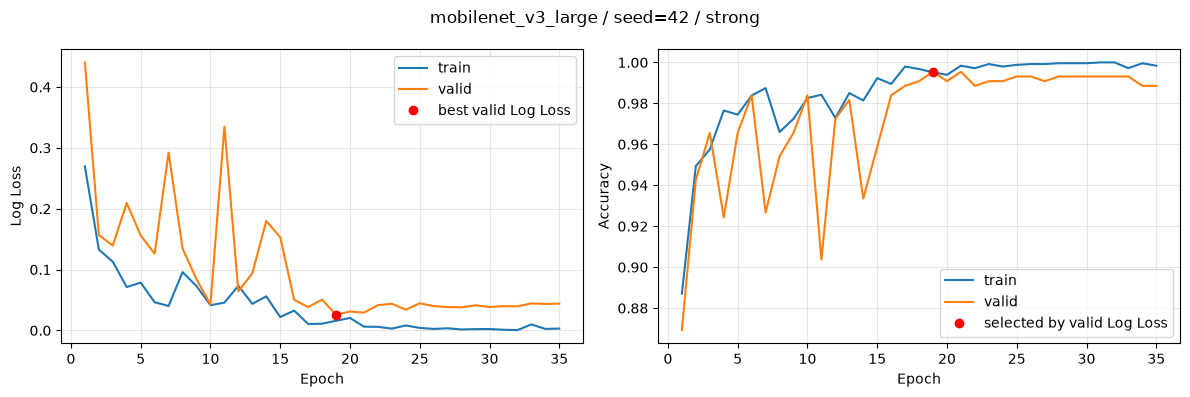

In [15]:
# 실제 실행은 프로젝트 루트에서 수행하고, 저장된 학습 코드를 실험 폴더에 복사합니다.
for filename in ("baseline_test2.ipynb", "model_test2.py"):
	shutil.copy2(BASE_DIR / filename, CODE_DIR / filename)

for seed in RUN_SEEDS[:1]:
	augmentation = AUGMENTATION_BY_SEED[seed]
	settings = AUGMENTATION_SETTINGS[augmentation]
	full_run_train = datasets.ImageFolder(data_path, train_transforms[augmentation])
	assert full_run_train.samples == full_train.samples, "이미지 순서 또는 라벨이 달라졌습니다."
	run_data_sets = {"train": Subset(full_run_train, train_idx), "valid": data_sets["valid"]}
	print(f"\n{'=' * 60}")
	print(f"모델: mobilenet_v3_large / seed: {seed} / 증강: {augmentation}", flush=True)
	seed_everything(seed)

	model = model_module.build_model("mobilenet_v3_large", pretrained=True).to(device)
	n_params = sum(p.numel() for p in model.parameters())
	assert n_params <= PARAM_LIMIT, f"파라미터 제한 초과: {n_params:,}"
	print(f"파라미터 수: {n_params:,}")

	# 모델 생성에서 소비한 난수와 데이터 로딩 난수를 분리합니다.
	seed_everything(seed)
	dataloaders = {
		"train": DataLoader(run_data_sets["train"], batch_size=params["batch_size"], shuffle=True, num_workers=params["workers"], generator=torch.Generator().manual_seed(seed)),
		"valid": DataLoader(run_data_sets["valid"], batch_size=params["batch_size"], shuffle=False, num_workers=params["workers"], generator=torch.Generator().manual_seed(seed)),
	}
	criterion = nn.BCEWithLogitsLoss()
	optimizer = torch.optim.Adam(model.parameters(), lr=params["learning_rates"][0])
	pt_file_name = CHECKPOINT_DIR / f"mobilenet_v3_large_seed{seed}.pt"

	if device.type == "cuda":
		torch.cuda.synchronize(device)
	started = time.perf_counter()

	with (EPOCH_DIR / f"mobilenet_v3_large_seed{seed}.csv").open("w", newline="", encoding="utf-8-sig") as epoch_csv:
		history, best_epoch, best_loss = train_model(model, dataloaders, criterion, optimizer, num_epochs=params["epoch"], epoch_csv=epoch_csv, early_stopping=params["early_stopping"], min_epochs=params["min_epochs"], patience=params["patience"], learning_rates=params["learning_rates"])

	if device.type == "cuda":
		torch.cuda.synchronize(device)
	elapsed = time.perf_counter() - started

	results.append({
		"model": "mobilenet_v3_large",
		"source_experiment": "008",
		"source_checkpoint": "",
		"reused": False,
		"split_seed": SEED,
		"seed": seed,
		"augmentation": augmentation,
		"selection_metric": "valid_loss",
		"image_size": IMG_SIZE,
		"preprocessing": "crop_then_aspect_resize_pad",
		"erase_p": settings["erase_p"],
		"erase_scale": "(0.02, 0.1)",
		"perspective_p": settings["perspective_p"],
		"distortion_scale": settings["distortion_scale"],
		"scale_min": settings["scale_min"],
		"brightness": settings["brightness"],
		"contrast": settings["contrast"],
		"saturation": settings["saturation"],
		"learning_rates": str(params["learning_rates"]),
		"valid_loss_first12": min(history["valid_loss"][:12]),
		"valid_acc_first12": max(history["valid_acc"][:12]),
		"max_epochs": params["epoch"],
		"epochs_run": len(history["train_loss"]),
		"early_stopping": params["early_stopping"],
		"min_epochs": params["min_epochs"],
		"patience": params["patience"],
		"best_epoch": best_epoch,
		"valid_loss": best_loss,
		"valid_acc": history["valid_acc"][best_epoch - 1],
		"seconds": elapsed,
		"n_params": n_params,
		"checkpoint": str(pt_file_name),
	})

	# 실험 도중 중단돼도 완료된 실행의 지표는 CSV에 남깁니다.
	with (RESULT_DIR / "runs.csv").open("w", newline="", encoding="utf-8-sig") as f:
		writer = csv.DictWriter(f, fieldnames=list(results[0]))
		writer.writeheader()
		writer.writerows(results)

	epochs = range(1, len(history["train_loss"]) + 1)
	fig, axes = plt.subplots(1, 2, figsize=(12, 4))
	axes[0].plot(epochs, history["train_loss"], label="train")
	axes[0].plot(epochs, history["valid_loss"], label="valid")
	axes[0].plot(best_epoch, best_loss, "ro", label="best valid Log Loss")
	axes[0].set_ylabel("Log Loss")
	axes[1].plot(epochs, history["train_acc"], label="train")
	axes[1].plot(epochs, history["valid_acc"], label="valid")
	axes[1].plot(best_epoch, history["valid_acc"][best_epoch - 1], "ro", label="selected by valid Log Loss")
	axes[1].set_ylabel("Accuracy")
	for ax in axes:
		ax.set_xlabel("Epoch")
		ax.legend()
		ax.grid(alpha=0.3)
	fig.suptitle(f"mobilenet_v3_large / seed={seed} / {augmentation}")
	fig.tight_layout()
	fig.savefig(GRAPH_DIR / f"mobilenet_v3_large_seed{seed}.png", dpi=160, bbox_inches="tight")
	plt.show()
	plt.close(fig)
	del optimizer, model, dataloaders


### 007 B0 재사용

같은 seed의 007 모델 세 개가 완료된 후 실행합니다.
완료 전이면 여기서 멈추며, 완료 후 아래 셀부터 이어 실행합니다.


In [16]:
source_runs_path = SOURCE_DIR / "runs.csv"
assert source_runs_path.is_file(), f"007 완료 기록이 없습니다: {source_runs_path}"
with source_runs_path.open(newline="", encoding="utf-8-sig") as f:
	source_runs = list(csv.DictReader(f))
reused_results = []
for seed, augmentation in zip(RUN_SEEDS[1:], ("strong", "erasing", "perspective")):
	matches = [row for row in source_runs if int(row["seed"]) == seed]
	assert len(matches) == 1, f"007 모델 seed {seed}의 완료 행이 한 개 필요합니다."
	row = dict(matches[0])
	assert row["model"] == "efficientnet_b0"
	assert int(row["split_seed"]) == SEED
	assert row["augmentation"] == augmentation
	assert row["selection_metric"] == "valid_loss"
	assert row["preprocessing"] == "crop_then_aspect_resize_pad"
	assert row["learning_rates"] == str(params["learning_rates"])
	assert int(row["max_epochs"]) == params["epoch"]
	assert int(row["min_epochs"]) == params["min_epochs"]
	assert int(row["patience"]) == params["patience"]
	assert row["early_stopping"] == str(params["early_stopping"])
	assert int(row["image_size"]) == IMG_SIZE
	for key, value in AUGMENTATION_SETTINGS[augmentation].items():
		assert float(row[key]) == value, f"007 설정 불일치: seed {seed}, {key}"
	for key in ("split_seed", "seed", "image_size", "max_epochs", "epochs_run", "min_epochs", "patience", "best_epoch", "n_params"):
		row[key] = int(row[key])
	for key in ("valid_loss", "valid_acc", "seconds", "valid_loss_first12", "valid_acc_first12"):
		row[key] = float(row[key])
	source_checkpoint = SOURCE_DIR / "checkpoints" / f"efficientnet_b0_seed{seed}.pt"
	assert source_checkpoint.is_file(), f"007 가중치가 없습니다: {source_checkpoint}"
	assert (SOURCE_DIR / "epochs" / f"efficientnet_b0_seed{seed}.csv").is_file()
	assert (SOURCE_DIR / "graphs" / f"efficientnet_b0_seed{seed}.png").is_file()
	row["source_experiment"] = "007"
	row["source_checkpoint"] = str(source_checkpoint)
	row["reused"] = True
	row["checkpoint"] = str(CHECKPOINT_DIR / source_checkpoint.name)
	reused_results.append(row)
for filename in ("baseline_test.ipynb", "model.py"):
	assert (SOURCE_DIR / "코드" / filename).is_file(), f"007 학습 코드가 없습니다: {filename}"
print("007 B0 재사용 준비 완료:", [row["seed"] for row in reused_results])

assert results and (results[0]["model"] == "mobilenet_v3_large")
results = results[:1]
for row in reused_results:
	shutil.copy2(row["source_checkpoint"], row["checkpoint"])
	seed = row["seed"]
	shutil.copy2(SOURCE_DIR / "epochs" / f"efficientnet_b0_seed{seed}.csv", EPOCH_DIR / f"efficientnet_b0_seed{seed}.csv")
	shutil.copy2(SOURCE_DIR / "graphs" / f"efficientnet_b0_seed{seed}.png", GRAPH_DIR / f"efficientnet_b0_seed{seed}.png")
	results.append(row)
	print(f"007 B0 재사용: seed {seed}, Log Loss {row['valid_loss']:.5f}")
with (RESULT_DIR / "runs.csv").open("w", newline="", encoding="utf-8-sig") as f:
	writer = csv.DictWriter(f, fieldnames=list(results[0]))
	writer.writeheader()
	writer.writerows(results)


007 B0 재사용 준비 완료: [43, 44, 45]
007 B0 재사용: seed 43, Log Loss 0.00280
007 B0 재사용: seed 44, Log Loss 0.00646
007 B0 재사용: seed 45, Log Loss 0.02361


### 구성 모델 기록

runs.csv는 새로 학습한 MobileNet과 재사용한 세 B0의 지표·출처를 기록합니다.
summary.csv의 네 모델 간 편차는 서로 다른 구성 모델의 기술 통계입니다.
동일 모델을 반복 학습한 성능 오차범위를 의미하지 않습니다.


In [17]:
assert len(results) == len(RUN_SEEDS), "모든 시드의 실행을 완료해야 합니다."

losses = np.array([row["valid_loss"] for row in results])
accuracies = np.array([row["valid_acc"] for row in results])
seconds = np.array([row["seconds"] for row in results])
summary = {
	"model": "mobilenet_v3_large+efficientnet_b0",
	"split_seed": SEED,
	"runs": len(results),
	"loss_mean": float(losses.mean()),
	"loss_std": float(losses.std(ddof=1)),
	"accuracy_mean": float(accuracies.mean()),
	"accuracy_std": float(accuracies.std(ddof=1)),
	"seconds_mean": float(seconds.mean()),
	"seconds_std": float(seconds.std(ddof=1)),
	"n_params": sum(row["n_params"] for row in results),
}
with (RESULT_DIR / "summary.csv").open("w", newline="", encoding="utf-8-sig") as f:
	writer = csv.DictWriter(f, fieldnames=list(summary))
	writer.writeheader()
	writer.writerow(summary)

print(f"검증 Log Loss: {summary['loss_mean']:.4f} ± {summary['loss_std']:.4f}")
print(f"검증 정확도: {summary['accuracy_mean']:.2%} ± {summary['accuracy_std']:.2%}")
print(f"이번 MobileNet 학습 시간: {results[0]['seconds'] / 60:.1f}분")
print("실행별 결과:", RESULT_DIR / "runs.csv")
print("전체 통계:", RESULT_DIR / "summary.csv")



검증 Log Loss: 0.0147 ± 0.0117
검증 정확도: 99.71% ± 0.34%
이번 MobileNet 학습 시간: 4.5분
실행별 결과: C:\Users\행조\OneDrive\문서\ChatGPT\aid mini 대회\실험결과\008_이종모델앙상블\seed_42\runs.csv
전체 통계: C:\Users\행조\OneDrive\문서\ChatGPT\aid mini 대회\실험결과\008_이종모델앙상블\seed_42\summary.csv


### 조건부 T0.3과 TTA 검증

각 모델에서 원본·좌우 반전 확률을 평균한 뒤 네 모델을 결합합니다.
전원 일치이면 네 확률 평균에 T=0.3, 불일치이면 가운데 두 확률 평균에 T=0.7을 적용합니다.
검증에서 TTA 유무별 손실·정확도·의견 일치 유형과 이미지별 예측을 저장합니다.


In [18]:
assert [row["seed"] for row in results] == list(RUN_SEEDS)
assert [row["model"] for row in results] == list(MODEL_NAMES)
ensemble_weights_path = RESULT_DIR / "ensemble.pt"
checkpoint = {
	"model_names": list(MODEL_NAMES),
	"seeds": list(RUN_SEEDS),
	"split_seed": SEED,
	"augmentations": [AUGMENTATION_BY_SEED[seed] for seed in RUN_SEEDS],
	"image_size": IMG_SIZE,
	"preprocessing": "aspect_resize_pad",
	"temperatures": [model_module.CONSENSUS_TEMPERATURE, model_module.DISAGREEMENT_TEMPERATURE],
	"source_experiments": [row["source_experiment"] for row in results],
	"state_dicts": [torch.load(row["checkpoint"], map_location="cpu", weights_only=True) for row in results],
}
ensemble = model_module.MixedEnsemble(checkpoint["model_names"], checkpoint["state_dicts"]).to(device).eval()
ensemble_params = sum(p.numel() for p in ensemble.parameters())
assert ensemble_params <= PARAM_LIMIT, f"앙상블 파라미터 제한 초과: {ensemble_params:,}"
torch.save(checkpoint, ensemble_weights_path)
valid_loader = DataLoader(data_sets["valid"], batch_size=params["batch_size"], shuffle=False, num_workers=0)
validation_probabilities, validation_tta_probabilities, validation_targets = [], [], []
with torch.inference_mode():
	for inputs, targets in valid_loader:
		inputs = inputs.to(device)
		member_probs = ensemble.member_probabilities(inputs).cpu()
		flipped_probs = ensemble.member_probabilities(inputs.flip(dims=[3])).cpu()
		validation_probabilities.append(member_probs)
		validation_tta_probabilities.append((member_probs + flipped_probs) / 2)
		validation_targets.append(targets)
member_probs = torch.cat(validation_probabilities)
tta_member_probs = torch.cat(validation_tta_probabilities)
targets = torch.cat(validation_targets).float()
ensemble_probs_by_rule = {
	"T0.3": model_module.combine_probabilities(member_probs),
	"T0.3_TTA": model_module.combine_probabilities(tta_member_probs),
}
mean_probs = member_probs.mean(dim=1, keepdim=True)
middle_probs = member_probs.sort(dim=1).values[:, 1:3].mean(dim=1, keepdim=True)
all_probs = torch.cat((member_probs, mean_probs, middle_probs, *ensemble_probs_by_rule.values()), dim=1)
names = [f"seed{seed}" for seed in RUN_SEEDS] + ["mean_T1", "middle_T1"] + list(ensemble_probs_by_rule)
metrics = []
for index, name in enumerate(names):
	probs = all_probs[:, index]
	row = {
		"model": name, "samples": len(targets),
		"valid_acc": ((probs >= 0.5) == targets.bool()).float().mean().item(),
		"valid_loss": torch.nn.functional.binary_cross_entropy(probs.clamp(1e-6, 1 - 1e-6), targets).item(),
	}
	metrics.append(row)
	print(f"{name}: ACC {row['valid_acc']:.2%} / Log Loss {row['valid_loss']:.5f}")
for filename, rows in (("ensemble_metrics.csv", metrics), ("comparison.csv", metrics[-4:])):
	with (RESULT_DIR / filename).open("w", newline="", encoding="utf-8-sig") as f:
		writer = csv.DictWriter(f, fieldnames=list(rows[0]))
		writer.writeheader()
		writer.writerows(rows)
agreement_metrics = []
votes_by_rule = {}
for rule, probabilities in (("T0.3", member_probs), ("T0.3_TTA", tta_member_probs)):
	votes = (probabilities >= 0.5).sum(dim=1)
	votes_by_rule[rule] = votes
	for name, mask in (("4:0", (votes == 0) | (votes == 4)), ("3:1", (votes == 1) | (votes == 3)), ("2:2", votes == 2)):
		count = int(mask.sum())
		row = {"rule": rule, "agreement": name, "samples": count, "valid_acc": None, "valid_loss": None}
		if count > 0:
			probs = ensemble_probs_by_rule[rule].squeeze(1)[mask]
			labels = targets[mask]
			row["valid_acc"] = ((probs >= 0.5) == labels.bool()).float().mean().item()
			row["valid_loss"] = torch.nn.functional.binary_cross_entropy(probs.clamp(1e-6, 1 - 1e-6), labels).item()
		agreement_metrics.append(row)
with (RESULT_DIR / "agreement_metrics.csv").open("w", newline="", encoding="utf-8-sig") as f:
	writer = csv.DictWriter(f, fieldnames=list(agreement_metrics[0]))
	writer.writeheader()
	writer.writerows(agreement_metrics)
with (RESULT_DIR / "validation_predictions.csv").open("w", newline="", encoding="utf-8-sig") as f:
	writer = csv.writer(f)
	header = ["id", "label", "positive_votes", "TTA_positive_votes", "T0.3_temperature", "TTA_temperature"]
	writer.writerow(header + [f"{name}_prob" for name in names] + [f"seed{seed}_TTA_prob" for seed in RUN_SEEDS])
	for position, sample_index in enumerate(valid_idx):
		temperatures = []
		for rule in ensemble_probs_by_rule:
			votes = int(votes_by_rule[rule][position])
			temperatures.append(model_module.CONSENSUS_TEMPERATURE if votes in (0, 4) else model_module.DISAGREEMENT_TEMPERATURE)
		image_id = Path(full_valid.samples[sample_index][0]).stem
		writer.writerow([image_id, int(targets[position]), int(votes_by_rule["T0.3"][position]), int(votes_by_rule["T0.3_TTA"][position])] + temperatures + all_probs[position].tolist() + tta_member_probs[position].tolist())
print(f"앙상블 파라미터: {ensemble_params:,}")
print("앙상블 가중치:", ensemble_weights_path)


seed42: ACC 99.54% / Log Loss 0.02573
seed43: ACC 100.00% / Log Loss 0.00280
seed44: ACC 100.00% / Log Loss 0.00647
seed45: ACC 99.31% / Log Loss 0.02357
mean_T1: ACC 99.77% / Log Loss 0.00798
middle_T1: ACC 99.77% / Log Loss 0.00581
T0.3: ACC 99.77% / Log Loss 0.00402
T0.3_TTA: ACC 99.77% / Log Loss 0.00420
앙상블 파라미터: 16,229,800
앙상블 가중치: C:\Users\행조\OneDrive\문서\ChatGPT\aid mini 대회\실험결과\008_이종모델앙상블\seed_42\ensemble.pt


## 테스트 추론 — 제출 CSV 두 개 생성

같은 가중치에서 조건부 T0.3과 조건부 T0.3 TTA를 생성합니다.


In [19]:
class TestImageDataset(Dataset):
    def __init__(self, files, transform):
        self.files = files
        self.transform = transform

    def __len__(self):
        return len(self.files)

    def __getitem__(self, index):
        file = self.files[index]
        img = Image.open(file).convert('RGB')
        return self.transform(img), os.path.basename(file)


import glob
test_files = sorted(glob.glob('./test/*'))
print('테스트 이미지 수:', len(test_files))

test_loader = DataLoader(
    TestImageDataset(test_files, valid_transform),
    batch_size=params['batch_size'], shuffle=False)

테스트 이미지 수: 500


In [20]:
submission_rows = {name: ["id,prob"] for name in ("T0.3", "T0.3_TTA")}
ensemble.eval()
with torch.inference_mode():
	for inputs, filenames in test_loader:
		inputs = inputs.to(device)
		member_probs = ensemble.member_probabilities(inputs).cpu()
		flipped_probs = ensemble.member_probabilities(inputs.flip(dims=[3])).cpu()
		probabilities = {
			"T0.3": model_module.combine_probabilities(member_probs).squeeze(1),
			"T0.3_TTA": model_module.combine_probabilities((member_probs + flipped_probs) / 2).squeeze(1),
		}
		for name, probs in probabilities.items():
			for filename, prob in zip(filenames, probs):
				submission_rows[name].append(f"{Path(filename).stem},{prob.item():.6f}")
with (BASE_DIR / "sample_submission.csv").open(newline="", encoding="utf-8-sig") as f:
	expected_ids = [row["id"] for row in csv.DictReader(f)]
assert len(expected_ids) == len(set(expected_ids)) == 500
submission_paths = {}
for name, rows in submission_rows.items():
	image_ids = [row.split(",")[0] for row in rows[1:]]
	assert len(image_ids) == len(set(image_ids)) == 500
	assert set(image_ids) == set(expected_ids), "테스트 ID가 sample_submission과 다릅니다."
	assert all(np.isfinite(float(row.split(",")[1])) and (0 <= float(row.split(",")[1]) <= 1) for row in rows[1:]), "비정상 확률이 있습니다."
	path = RESULT_DIR / f"submission_{SEED}_{name}.csv"
	path.write_text("\n".join(rows) + "\n", encoding="utf-8")
	submission_paths[name] = path
	print("제출 CSV:", path)


제출 CSV: C:\Users\행조\OneDrive\문서\ChatGPT\aid mini 대회\실험결과\008_이종모델앙상블\seed_42\submission_42_T0.3.csv
제출 CSV: C:\Users\행조\OneDrive\문서\ChatGPT\aid mini 대회\실험결과\008_이종모델앙상블\seed_42\submission_42_T0.3_TTA.csv


## 제출 패키지

baseline_test2.ipynb·model_test2.py·predict_test2.py·model.pt를 포함합니다.
source_007/에는 재사용한 B0의 학습 노트북과 모델 코드를 포함하고, runs.csv에 가중치 출처를 기록합니다.

```shell
python predict_test2.py --input test --output pred.csv
python predict_test2.py --input test --output pred_tta.csv --tta
```


In [21]:
%%writefile predict_test2.py
import argparse
from pathlib import Path

import torch
from PIL import Image
from model_test2 import IMG_SIZE, MixedEnsemble, build_valid_transform

PARAM_LIMIT = 20_000_000


def main():
	parser = argparse.ArgumentParser()
	parser.add_argument("--input", required=True, help="테스트 이미지 폴더")
	parser.add_argument("--output", required=True, help="출력 CSV 경로")
	parser.add_argument("--weights", default="model.pt", help="앙상블 가중치 파일")
	parser.add_argument("--tta", action="store_true", help="원본·좌우 반전 확률 평균 후 조건부 T0.3 적용")
	args = parser.parse_args()
	weights_path = Path(__file__).resolve().parent / args.weights
	checkpoint = torch.load(weights_path, map_location="cpu", weights_only=True)
	assert checkpoint["image_size"] == IMG_SIZE, "입력 크기가 다릅니다."
	model = MixedEnsemble(checkpoint["model_names"], checkpoint["state_dicts"]).eval()
	n_params = sum(p.numel() for p in model.parameters())
	assert n_params <= PARAM_LIMIT, f"파라미터 20M 초과: {n_params:,}"
	transform = build_valid_transform()
	files = sorted(p for p in Path(args.input).iterdir() if p.suffix.lower() in (".jpg", ".jpeg", ".png"))
	assert len(files) > 0, "테스트 이미지가 없습니다."
	rows = ["id,prob"]
	with torch.inference_mode():
		for start in range(0, len(files), 32):
			batch_files = files[start:start + 32]
			images = []
			for file in batch_files:
				with Image.open(file) as image:
					images.append(transform(image.convert("RGB")))
			probs = model(torch.stack(images), tta=args.tta).squeeze(1)
			for file, prob in zip(batch_files, probs):
				rows.append(f"{file.stem},{prob.item():.6f}")
	Path(args.output).write_text("\n".join(rows) + "\n", encoding="utf-8")
	print(f"{args.output} 저장 완료 ({len(files)}장, 파라미터 {n_params:,})")


if __name__ == "__main__":
	main()


Overwriting predict_test2.py


In [22]:
package_dir = RESULT_DIR / "package"
assert package_dir.resolve().parent == RESULT_DIR.resolve()
package_dir.mkdir(exist_ok=True)
shutil.copy2(BASE_DIR / "predict_test2.py", CODE_DIR / "predict_test2.py")
for filename in ("model_test2.py", "predict_test2.py", "baseline_test2.ipynb"):
	shutil.copy2(CODE_DIR / filename, package_dir / filename)
source_code_dir = package_dir / "source_007"
source_code_dir.mkdir(exist_ok=True)
for filename in ("baseline_test.ipynb", "model.py"):
	shutil.copy2(SOURCE_DIR / "코드" / filename, source_code_dir / filename)
shutil.copy2(RESULT_DIR / "runs.csv", package_dir / "runs.csv")
shutil.copyfile(ensemble_weights_path, package_dir / "model.pt")
zip_path = shutil.make_archive(str(RESULT_DIR / "submission_package"), "zip", package_dir)
assert Path(zip_path).stat().st_size <= 200_000_000, "ZIP 200MB 초과"
print("앙상블 패키지 생성:", zip_path)


앙상블 패키지 생성: C:\Users\행조\OneDrive\문서\ChatGPT\aid mini 대회\실험결과\008_이종모델앙상블\seed_42\submission_package.zip


### 패키지 CPU 자가 검증

패키지의 추론 코드로 두 CSV를 각각 재현하고 최대 확률 차이를 확인합니다.
Colab CPU의 500장 600초 제한은 실제 Colab에서도 확인합니다.


In [23]:
import sys
subprocess_env = os.environ.copy()
subprocess_env["PYTHONIOENCODING"] = "utf-8"
for name, use_tta in (("T0.3", False), ("T0.3_TTA", True)):
	package_check_path = RESULT_DIR / f"package_check_{SEED}_{name}.csv"
	command = [sys.executable, str(package_dir / "predict_test2.py"), "--input", str(BASE_DIR / "test"), "--output", str(package_check_path)]
	if use_tta:
		command.append("--tta")
	started = time.perf_counter()
	result = subprocess.run(command, capture_output=True, text=True, encoding="utf-8", check=True, env=subprocess_env)
	elapsed = time.perf_counter() - started
	print(result.stdout)
	print(result.stderr)
	print(f"{name} CPU 추론 시간: {elapsed:.1f}초")
	assert elapsed <= 600, "CPU 추론 10분 초과"
	with submission_paths[name].open(newline="", encoding="utf-8") as f:
		nb_probs = {row["id"]: float(row["prob"]) for row in csv.DictReader(f)}
	with package_check_path.open(newline="", encoding="utf-8") as f:
		pkg_probs = {row["id"]: float(row["prob"]) for row in csv.DictReader(f)}
	assert nb_probs.keys() == pkg_probs.keys(), "파일 목록이 다릅니다."
	max_diff = max(abs(nb_probs[key] - pkg_probs[key]) for key in nb_probs)
	print(f"{name} 노트북 vs 패키지 확률 최대 차이: {max_diff:.2e}")
	assert max_diff < 1e-3, "전처리·가중치·앙상블·CPU/GPU 수치 차이를 확인하세요."
print("조건부 T0.3과 TTA 패키지 자가 검증 통과")


C:\Users\행조\OneDrive\문서\ChatGPT\aid mini 대회\실험결과\008_이종모델앙상블\seed_42\package_check_42_T0.3.csv 저장 완료 (500장, 파라미터 16,229,800)


T0.3 CPU 추론 시간: 16.3초
T0.3 노트북 vs 패키지 확률 최대 차이: 1.00e-06
C:\Users\행조\OneDrive\문서\ChatGPT\aid mini 대회\실험결과\008_이종모델앙상블\seed_42\package_check_42_T0.3_TTA.csv 저장 완료 (500장, 파라미터 16,229,800)


T0.3_TTA CPU 추론 시간: 27.8초
T0.3_TTA 노트북 vs 패키지 확률 최대 차이: 2.00e-06
조건부 T0.3과 TTA 패키지 자가 검증 통과


## 실행 확인

- 시작 SEED는 42이며 SEED=1로 변경해 같은 실험을 반복할 수 있습니다.
- 007의 동일 분할·모델 seed에 해당하는 세 B0가 완료돼 있어야 합니다.
- 추가 학습은 MobileNet 한 개입니다.
- 두 제출 CSV가 테스트 500개 ID와 유효한 확률을 포함하는지 확인합니다.
- 최종 선택 방식으로 CPU 재현과 추론 10분 제한을 확인합니다.
